# SGD vs Adam

### Learning Object:

Understanding why neural networks use optimisation algorithms and how different optimisers update model parameters.

In [46]:
import copy
import torch
import matplotlib.pyplot as plt

In [47]:
torch.manual_seed(42)

In [48]:
# Dataset
X = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
Y = torch.tensor([[3.0], [5.0], [7.0], [9.0]])

In [49]:
# Create a base model
base_model = torch.nn.Linear(1, 1)

In [50]:
# Two models with identical initial params
sgd_model = copy.deepcopy(base_model)
adam_model = copy.deepcopy(base_model)

In [51]:
# Optimisers
sgd_optimizer = torch.optim.SGD(
    sgd_model.parameters(), lr=0.01
)

adam_optimizer = torch.optim.Adam(
    adam_model.parameters(), lr=0.01
)

loss_fn = torch.nn.MSELoss()

In [52]:
# Training function
def train_model(model, optimizer, X, Y, loss_fn, epochs):
    losses = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_fn(predictions, Y)

        loss.backward()
        optimizer.step()
        
        losses.append(loss.item())

    return losses

In [53]:
# Train both models for 1000 epochs
epochs = 1000
sgd_losses = train_model(sgd_model, sgd_optimizer, X, Y, loss_fn, epochs)
adam_losses = train_model(adam_model, adam_optimizer, X, Y, loss_fn, epochs)

In [54]:
print("SGD  -> weight:", sgd_model.weight.item(), "bias:", sgd_model.bias.item())
print("Adam -> weight:", adam_model.weight.item(), "bias:", adam_model.bias.item())

SGD  -> weight: 1.9961960315704346 bias: 1.0111840963363647
Adam -> weight: 1.9400367736816406 bias: 1.1709097623825073


In [55]:
print("SGD  final loss:", sgd_losses[-1])
print("Adam final loss:", adam_losses[-1])

SGD  final loss: 2.1015859601902775e-05
Adam final loss: 0.004961703438311815


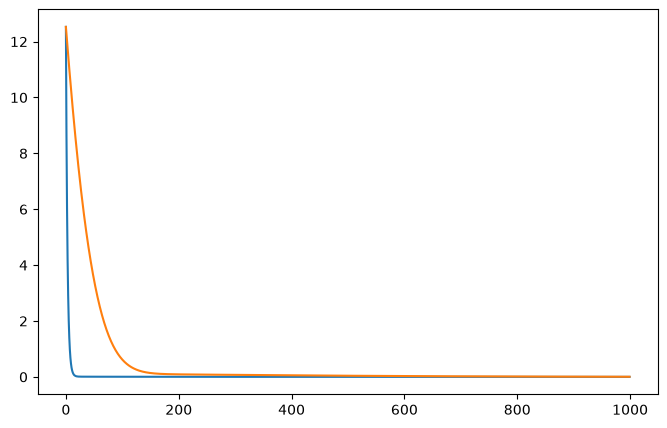

In [56]:
# Visualize the loss curves
plt.figure(figsize=(8, 5))
plt.plot(sgd_losses, label="SGD")
plt.plot(adam_losses, label="Adam")


### Observations - Linear Scale

From the graph we can see that SGD curve drops sharply and becomes almost indistinguishable from zero.

The problem with this graph is that once the loss becomes small, it becomes difficult to distinguish the remaining differences.

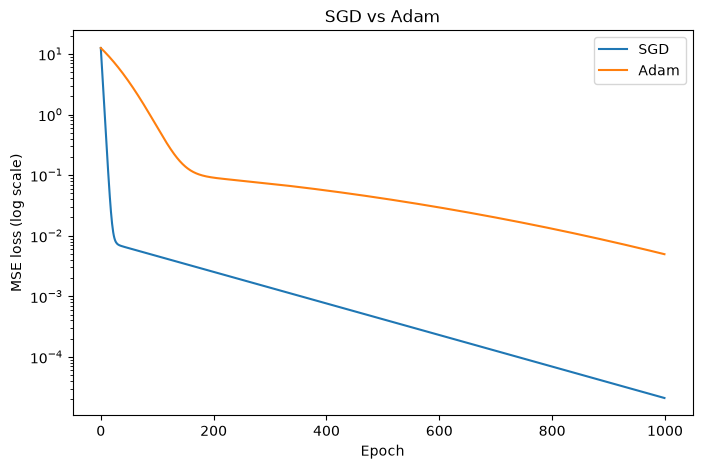

In [57]:

plt.figure(figsize=(8, 5))

plt.plot(sgd_losses, label="SGD")
plt.plot(adam_losses, label="Adam")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (log scale)")
plt.title("SGD vs Adam")
plt.legend()
plt.show()


### Observations - Logarithmic scale

- SGD: drops sharply, then continues steadily decreasing
- Adam: initially decreases, slows down around 10^-1, then gradually decreases further.
- by epoch 1000 SGD has achieved a substantially lower loss than Adam.

The logarithmic scale makes small loss values visible.